In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.interpolate import griddata
from scipy.interpolate import RegularGridInterpolator


# DATA 



In [3]:
''' GEOMETRY & MASS '''
m_curb = 1195 #kg
m_driver = 75 #kg
m_ice = 120
m = m_curb + m_driver + m_ice #kg
length = 3.999 #m
width = 1.775 #m
height = 1.597 #m
L = 2.570 #m
b_cg = 0.56*L #m
c_cg = 0.44*L #m
h_cg = 0.49 #m

'''TRANSMISSION & TIRE '''
# 19 inches rim; /39.37 converts inches in meters; 0.7*155 is thickness of tire
D_wheel = (( 19 / 39.37 ) + ( 155 * 0.7 * 2)*10**-3)
eta_t = 0.95 #-
i_gear = 9.665 #-
f0 = 0.008
f2 = 0.4e-7
R_e = 0.339 #m

''' ENGINE '''
P_1p = 125e3 #W
P_1n = 75e3 #W
C_max = 250 #Nm
omega_b = 4800 * (2*np.pi / 60) #rad/s
E_bat = 22.6e3 #Wh
J_mot = 0.025 #kg m^2

'''RANGE EXTENDER'''
P1_ice = 28e3 #W
omega1_ice = 5000 * (2*np.pi/60) #RPM
C2_ice = 56 #Nm
omega2_ice = 4500 * (2*np.pi/60) #RPM
n_cyl = 2
V_d = 647e-6 #m**3
stroke = 66 #mm
bore = 79 #mm
P_max_gen = 26.6e3 #W
fuel_tank = 9 #L
i_gen = 2
eta_ice_to_gen = 0.975


''' OTHER '''
g = 9.81 #m/s**2
rho = 1.23 #kg/m**3
S = 2.38 #m**2
C_x = 0.3 #-

''' GENERATOR '''
C_max_gen = 80 #Nm (based on figure in statement, approximation)
omega_b_gen = 5000 * (2*np.pi/60) #rad/s (based on figure in statement, approximation)
rpm_b_gen = 5000 # RPM
P_max_gen = C_max_gen * omega_b_gen #W

# ENGINE CURVES

In [4]:
rpm_ice = np.linspace(500, 5000, 10000)
omega_ice = rpm_ice*(2*np.pi/60)

''' POWER LAW APPROXIMATION '''

P1 = P1_ice
P2 = C2_ice * omega2_ice
b = ( (omega1_ice/omega2_ice) - 1 ) / ( (P1/P2) - 1 )
a = (P1 - P2) / (np.abs(omega1_ice - omega2_ice)**b)
P_law = P1 - a*np.abs(omega_ice-omega1_ice)**b
C_law = P_law/omega_ice

''' POLYNOMIAL FIT OF ORDER 3 '''

n2 = omega2_ice/omega1_ice
A_3 = np.array([
    [1,1,1],
    [n2,n2**2,n2**3],
    [0,1,2*n2]
])
B_3 = np.array([
    1,
    P2/P1,
    0
])
X = np.linalg.solve(A_3,B_3)
a0 = 0
a1,a2,a3 = X
P_poly3 = P1* (a0 + a1*(omega_ice/omega1_ice) + a2*(omega_ice/omega1_ice)**2 + a3*(omega_ice/omega1_ice)**3)
C_poly3 = P_poly3/omega_ice

''' POLYNOMIAL FIT OF ORDER 4 '''
A_4 = np.array([
    [1,1,1,1],
    [1,2,3,4],
    [n2,n2**2,n2**3,n2**4],
    [0,1,2*n2,3*n2**2]
])
B_4 = np.array([
    1,
    0,
    P2/P1,
    0
])
Y = np.linalg.solve(A_4,B_4)
a11,a22,a33,a44 = Y
P_poly4 = P1* (a0 + a11*(omega_ice/omega1_ice) + a22*(omega_ice/omega1_ice)**2 + a33*(omega_ice/omega1_ice)**3 + a44*(omega_ice/omega1_ice)**4)
C_poly4 = P_poly4/omega_ice

''' FINAL TUNED CURVES BASED ON POLYNOMIAL FIT OF ORDER 4 '''

idx2500rpm = np.argmin(np.abs(rpm_ice - 2500))
P_below2500 = P_poly4[idx2500rpm]
C_below2500 = C_poly4[idx2500rpm]

P_final = np.zeros(len(rpm_ice))
C_final = np.zeros(len(rpm_ice))

for i in range(len(rpm_ice)):
    if rpm_ice[i] >= 2500:
        P_final[i] = P_poly4[i]
        C_final[i] = C_poly4[i]
    else :
        P_final[i] = C_below2500 * omega_ice[i]
        C_final[i] = C_below2500


# PLOTS

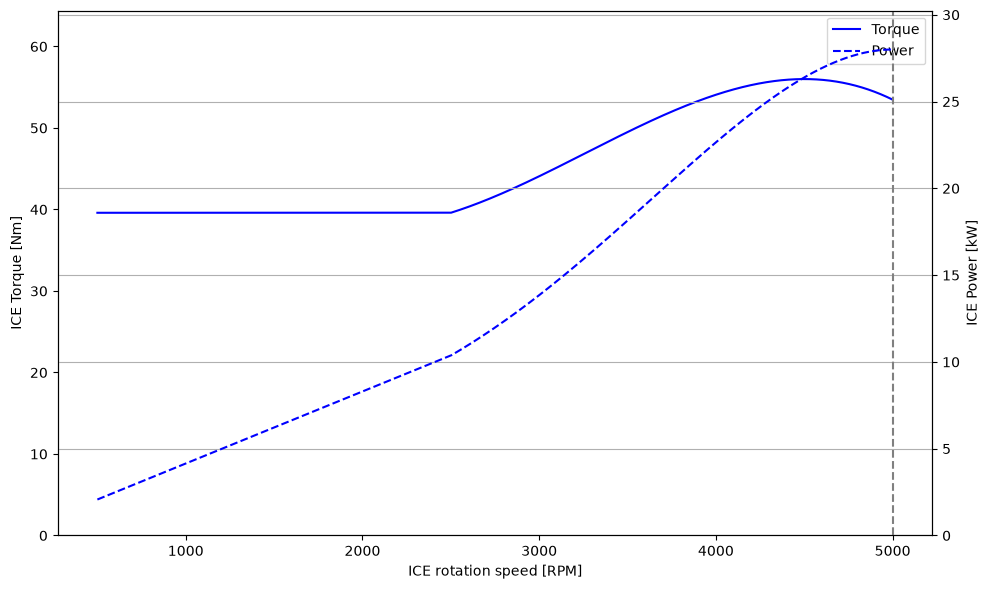

In [5]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Left axis : Torques
line1 = ax1.plot(rpm_ice, C_final, label='Torque', color='blue')
ax1.set_xlabel('ICE rotation speed [RPM]')
ax1.set_ylabel('ICE Torque [Nm]')
ax1.tick_params(axis='y')

# Right axis : Powers
ax2 = ax1.twinx()
line2 = ax2.plot(rpm_ice, P_final*10**-3, linestyle='--', label='Power', color='blue')
ax2.set_ylabel('ICE Power [kW]')
ax2.tick_params(axis='y')
ax2.grid(False) # Either 2 grids mixed, awful

# Scaling
ax1.set_ylim(0, C2_ice * 1.15)
ax2.set_ylim(0, (P1_ice*10**-3) * 1.08)

# Base speed
plt.axvline(x=rpm_b_gen, linestyle='dashed', color='gray', label='Base speed')

# Legend
lines = line1 + line2 
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels)
plt.tight_layout()
plt.grid(True)
plt.show()

# BSFC


In [6]:
c0 = 4.726e2
c1 = -5.426e-2
c2 = -7.736
c3 = 9.845e-6
c4 = 1.308e-4
c5 = 9.346e-2

rpm_grid_ice = np.linspace(500, 5000, 6000)
T_grid_ice = np.linspace(0, 56, 6000)
rpm_grid_ice, T_grid_ice = np.meshgrid(rpm_grid_ice, T_grid_ice)

bsfc = c0 + c1*rpm_grid_ice + c2*T_grid_ice + c3*rpm_grid_ice**2 + c4*rpm_grid_ice*T_grid_ice + c5*T_grid_ice**2

# PLOTS

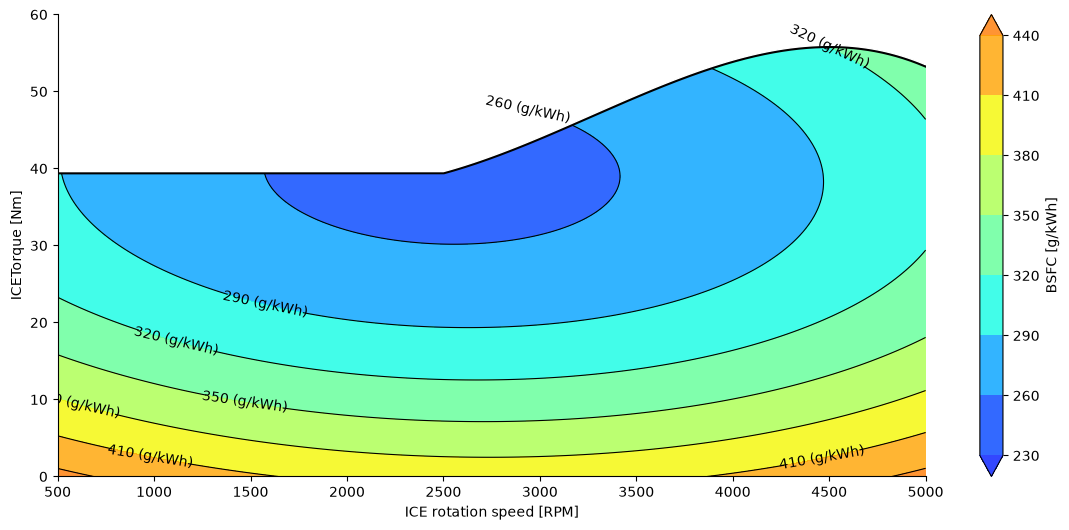

In [7]:
fig, ax = plt.subplots(figsize=(14, 6))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Contour lines of BSFC (lowest value, largest value, step)
levels = np.arange(230, 450, 30)
cs = ax.contour(rpm_grid_ice, T_grid_ice, bsfc, levels=levels, colors='k', linewidths=0.8, alpha=1)
ax.clabel(cs, inline=True, fontsize=10, fmt='%1.0f (g/kWh)')

# Special Color map
cmap_eff = LinearSegmentedColormap.from_list('jet_soft', plt.cm.jet(np.linspace(0.15, 0.78, 256)))
cf = ax.contourf(rpm_grid_ice, T_grid_ice, bsfc, levels=levels, cmap=cmap_eff, alpha=0.8, extend='both')
fig.colorbar(cf, ax=ax, label='BSFC [g/kWh]')

ax.plot(rpm_ice, C_final, color='black', linewidth=4)
ax.fill_between(rpm_ice, C_final, 500, color='white', zorder=2) # Hide above torque curve
ax.set_xlim(500, 5000)
ax.set_ylim(0, 60)
ax.set_xlabel('ICE rotation speed [RPM]')
ax.set_ylabel('ICETorque [Nm]')
plt.show()

# EFFICIENCY

In [8]:
rpm_gen = np.linspace(1, 12000, 10000)
omega_gen = rpm_gen*(2*np.pi/60)

''' GENERATOR TORQUE AND POWER CURVES '''

C_gen = np.zeros_like(omega_gen)
P_gen = np.zeros_like(omega_gen)
for i in range(len(omega_gen)):
    if omega_gen[i] <= omega_b_gen:
        C_gen[i] = C_max_gen
        P_gen[i] = C_max_gen * omega_gen[i]
    else:
        P_gen[i] = P_max_gen
        C_gen[i] = P_max_gen / omega_gen[i]


''' EFFICIENCY MAP '''

d0 = 9.071e-1
d1 = 1.358e-5
d2 = 1.149e-3
d3 = -3.662e-9
d4 = 6.036e-7
d5 = -6.612e-5
d6 = 1.734e-13
d7 = -1.434e-11
d8 = -3.817e-9
d9 = 5.683e-7

rpm_grid_gen = np.linspace(0, 12000, 6000)
T_grid_gen = np.linspace(0, 80, 6000)
rpm_grid_gen, T_grid_gen = np.meshgrid(rpm_grid_gen, T_grid_gen)

eta_gen = d0 + d1*rpm_grid_gen + d2*T_grid_gen + d3*rpm_grid_gen**2 + d4*rpm_grid_gen*T_grid_gen + d5*T_grid_gen**2 + d6*rpm_grid_gen**3 + d7*rpm_grid_gen**2 * T_grid_gen + d8*rpm_grid_gen*T_grid_gen**2 + d9*T_grid_gen**3

# PLOTS

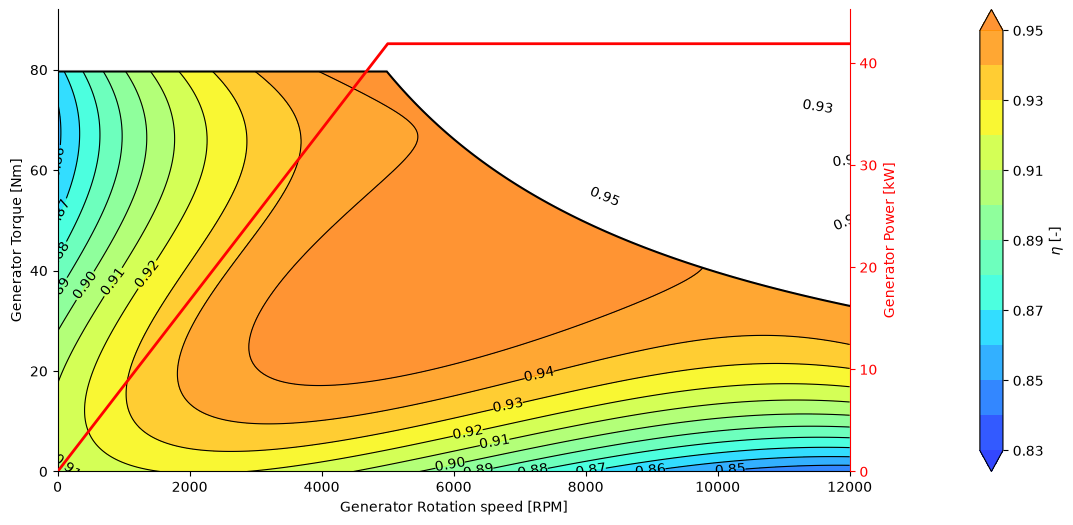

In [9]:
fig, ax = plt.subplots(figsize=(14, 6))
ax2 = ax.twinx()                             # axe de droite = puissance

# Contour lines of effciency (lowest value, largest value, step)
levels = np.arange(0.83, 0.96, 0.01)
cs = ax.contour(rpm_grid_gen, T_grid_gen, eta_gen, levels=levels, colors='k', linewidths=0.8, alpha=1)
ax.clabel(cs, inline=True, fontsize=10)

# Color map
cf = ax.contourf(rpm_grid_gen, T_grid_gen, eta_gen, levels=levels, cmap=cmap_eff, alpha=0.8, extend='both')
fig.colorbar(cf, ax=ax, pad=0.12, label=r'$\eta$ [-]') # Avoir color bar in power axis

# Torque
ax.plot(rpm_gen, C_gen, color='black', linewidth=4)
ax.fill_between(rpm_gen, C_gen, 500, color='white', zorder=2)

# Power
ax2.plot(rpm_gen, P_gen*10**-3, color='red', linewidth=2)


ax.set_xlim(0, 12000)
ax.set_ylim(0, C_max_gen * 1.15)
ax2.set_ylim(0, P_max_gen * 10**-3 * 1.08)
ax.set_xlabel('Generator Rotation speed [RPM]')
ax.set_ylabel('Generator Torque [Nm]')
ax2.set_ylabel('Generator Power [kW]', color='red')
ax2.tick_params(axis='y', colors='red')

# Spines
ax.spines[['top', 'right']].set_visible(False)
ax2.spines[['top', 'left', 'bottom']].set_visible(False)
ax2.spines['right'].set_color('red')

plt.show()

# ELECTRICAL POWER

In [10]:
''' ELECTRICAL POWER OUT OF GENERATOR'''

P_el = np.zeros(len(omega_ice)) # variation of electrical power wrt to ICE working point

rpm_el = rpm_grid_gen[0, :]  
T_el = T_grid_gen[:, 0]

for i in range(len(omega_ice)):
  # Impact of reduction ratio from ICE to generator
  omega_ice_to_gen = omega_ice[i] * i_gen
  torque_ice_to_gen = C_final[i] / i_gen

  # Indices in generator map
  idx_omega = np.argmin(np.abs(rpm_el - omega_ice_to_gen))
  idx_torque = np.argmin(np.abs(T_el - torque_ice_to_gen))

  # Efficiency value
  efficiency = eta_gen[idx_omega, idx_torque]  
  
  P_el[i] = omega_ice[i] * C_final[i] * eta_ice_to_gen * efficiency


# PLOTS


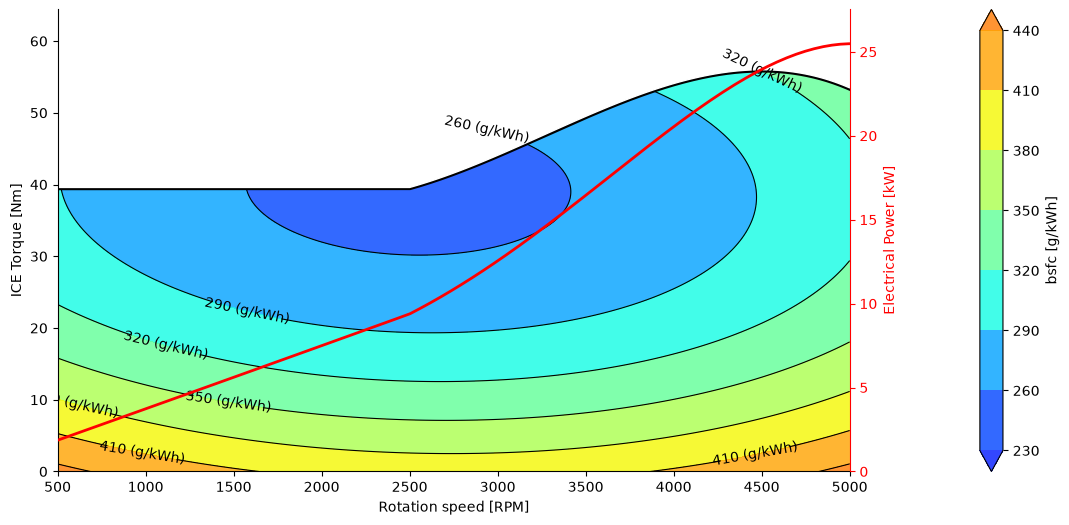

In [11]:
fig, ax = plt.subplots(figsize=(14, 6))
ax2 = ax.twinx()                             # axe de droite = puissance

# Cartographie de rendement (axe couple)
levels = np.arange(230, 450, 30)
cf = ax.contourf(rpm_grid_ice, T_grid_ice, bsfc, levels=levels, cmap=cmap_eff, alpha=0.8, extend='both')
cs = ax.contour(rpm_grid_ice, T_grid_ice, bsfc, levels=levels, colors='k', linewidths=0.8, alpha=1)
ax.clabel(cs, inline=True, fontsize=10, fmt='%1.0f (g/kWh)')

# Courbe de couple + masque blanc au-dessus
ax.plot(omega_ice / (2 * np.pi) * 60, C_final, color='black', linewidth=4)
ax.fill_between(omega_ice / (2 * np.pi) * 60, C_final, 500, color='white', zorder=2)

# Courbe de puissance (axe de droite)
ax2.plot(omega_ice / (2 * np.pi) * 60, P_el*10**-3, color='red', linewidth=2)

# Limites
ax.set_xlim(500, 5000)
ax.set_ylim(0, np.max(C_final) * 1.15)
ax2.set_ylim(0, np.max(P_el) * 10**-3 * 1.08)

# Labels
ax.set_xlabel('Rotation speed [RPM]')
ax.set_ylabel('ICE Torque [Nm]')
ax2.set_ylabel('Electrical Power [kW]', color='red')
ax2.tick_params(axis='y', colors='red')

# Spines
ax.spines[['top', 'right']].set_visible(False)
ax2.spines[['top', 'left', 'bottom']].set_visible(False)
ax2.spines['right'].set_color('red')

# Colorbar décalée pour ne pas chevaucher l'axe de puissance
fig.colorbar(cf, ax=ax, pad=0.12, label=r'bsfc [g/kWh]')

plt.show()

# BATTERY MANAGEMENT STRATEGY

In [12]:
''' BEST EFFICIENT ICE OPERATING POINT SELECTION'''

# Extracting all operating points (rpm,torque) inside sweet spot (bsfc <= 260)
mask = bsfc <= 260
rpm_extracted = rpm_grid_ice[mask]
T_extracted = T_grid_ice[mask]
bsfc_extracted = bsfc[mask]

# Final matrix will be such that each row correponds to a point (rpm, torque, efficiency, P_el)
matrix_data = np.column_stack((rpm_extracted, T_extracted))

# From ICE to generator
rpm_1d_gen = np.linspace(0, 12000, 6000)
T_1d_gen = np.linspace(0, 80, 6000)

eta_gen_interpolator = RegularGridInterpolator(
    (T_1d_gen, rpm_1d_gen), eta_gen, bounds_error=False, fill_value=None
) #interpolation to have values for every point

rpm_gen_vals = rpm_extracted * i_gen
omega_gen_vals = rpm_gen_vals * (2 * np.pi / 60)
T_gen_vals = T_extracted * eta_ice_to_gen / i_gen

points_gen = np.column_stack((T_gen_vals, rpm_gen_vals)) #instead of a loop that runs each point
eta_gen_vals = eta_gen_interpolator(points_gen)

# Final matrix update
matrix_data = np.column_stack((matrix_data, eta_gen_vals))

# Electrical power
P_mech_gen_vals = T_gen_vals * omega_gen_vals
P_el_vals = P_mech_gen_vals * eta_gen_vals

# Final matrix final update
matrix_data = np.column_stack((matrix_data, P_el_vals))

# Since criterion is to maximize driving range, the operating should be such that
# the amount of fuel consumed to produce 1 kWh of electrical energy is minimum.
# Introduction of electrical equivalent bsfc considering efficiencies 
bsfc_el_vals = bsfc_extracted / (eta_ice_to_gen * eta_gen_vals)

best_idx = np.argmin(bsfc_el_vals)
best_row = matrix_data[best_idx]

# Affichage des résultats pour le meilleur point
print("--- Best operating point to maximize driving range ---")
#print(f"Line index : {best_idx}")
print(f"ICE Rotation speed : {best_row[0]:.2f} RPM")
print(f"ICE Torque : {best_row[1]:.2f} Nm")
print(f"Generator Efficiency : {best_row[2]*100:.2f} %")
print(f"Electrical Power (P_el) : {best_row[3]:.2f} W")
print(f"Electrical Equivalent BSFC : {bsfc_el_vals[best_idx]:.2f} g/kWh")

--- Best operating point to maximize driving range ---
ICE Rotation speed : 2431.57 RPM
ICE Torque : 40.42 Nm
Generator Efficiency : 95.17 %
Electrical Power (P_el) : 9550.76 W
Electrical Equivalent BSFC : 271.28 g/kWh


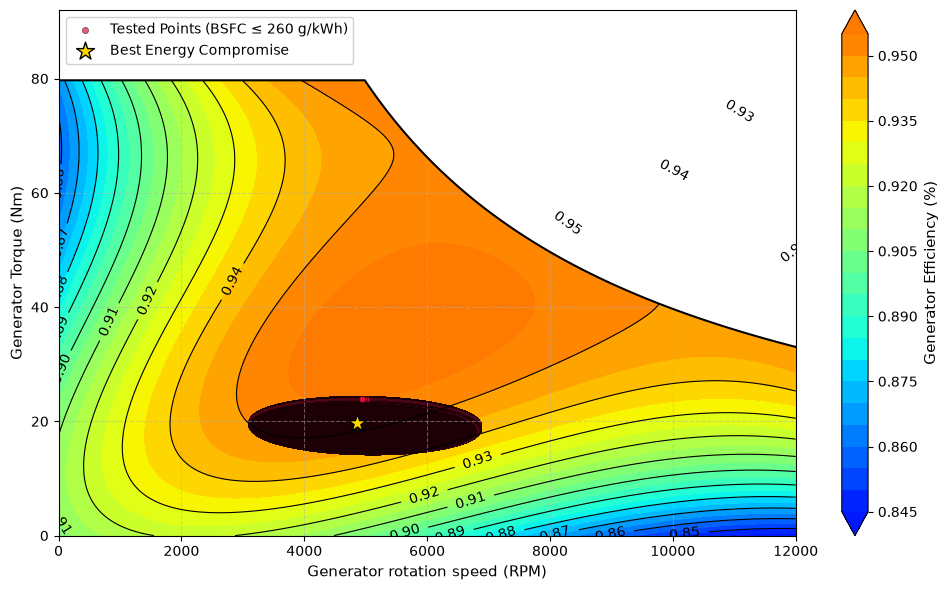

In [13]:
plt.figure(figsize=(10, 6))

RPM_grid_gen, T_grid_gen_map = np.meshgrid(rpm_1d_gen, T_1d_gen)

# Efficiency map
contour = plt.contourf(
    RPM_grid_gen,
    T_grid_gen_map,
    eta_gen,
    levels=25,
    cmap=cmap_eff,
    origin="lower",
    extend="both",
)
cbar = plt.colorbar(contour)
cbar.set_label("Generator Efficiency (%)", fontsize=11)

levels = np.arange(0.83, 0.96, 0.01)
cs = plt.contour(rpm_grid_gen, T_grid_gen, eta_gen, levels=levels, colors='k', linewidths=0.8, alpha=1)
plt.clabel(cs, inline=True, fontsize=10)

plt.plot(rpm_gen, C_gen, color='black', linewidth=4)
plt.fill_between(rpm_gen, C_gen, 500, color='white', zorder=2)

# Operating points tested
plt.scatter(
    rpm_gen_vals,
    T_gen_vals,
    color="crimson",
    s=20,
    alpha=0.7,
    edgecolors="k",
    linewidths=0.4,
    label="Tested Points (BSFC ≤ 260 g/kWh)",
)

# Best efficient operating point
best_rpm_gen = best_row[0] * i_gen
best_T_gen = best_row[1] * eta_ice_to_gen / i_gen
plt.scatter(
    best_rpm_gen,
    best_T_gen,
    color="gold",
    s=180,
    marker="*",
    edgecolors="black",
    linewidths=1,
    zorder=5,
    label="Best Energy Compromise",
)


plt.xlabel("Generator rotation speed (RPM)", fontsize=11)
plt.ylabel("Generator Torque (Nm)", fontsize=11)
plt.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.ylim(0, np.max(C_gen) * 1.15)

plt.tight_layout()
plt.show()